# Entrega 3 · Modelo predictivo — Supermercados Alianza Colombia S.A.
**Pregunta BA:** ¿cuántas ventas netas tendrá cada sede, por categoría de producto, en las próximas semanas?
**Decisión que apoya:** cuánto pedir a los proveedores por sede y categoría para la semana siguiente.

Fases: comprensión del negocio → comprensión de los datos → preparación → modelado → evaluación → despliegue.
El notebook se conecta al data warehouse MySQL `dw_alianza` (Entrega 2). La contraseña se toma de la variable de entorno `DB_PASS`; nunca se escribe en el notebook.

In [1]:
import os
from getpass import getpass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)
SEMILLA = 42

DB = dict(host=os.getenv('DB_HOST', 'localhost'), port=os.getenv('DB_PORT', '3307'),
          name=os.getenv('DB_NAME', 'dw_alianza'), user=os.getenv('DB_USER', 'bi_alianza'),
          pwd=os.getenv('DB_PASS') or getpass('Contraseña de MySQL (usuario bi_alianza): '))
engine = create_engine(f"mysql+pymysql://{DB['user']}:{DB['pwd']}@{DB['host']}:{DB['port']}/{DB['name']}")
with engine.connect() as c:
    print('Conectado a', c.execute(text('SELECT DATABASE(), VERSION()')).fetchone())

Conectado a ('dw_alianza', '8.0.44')


## 1. Comprensión de los datos
### 1.1 Extracción desde el data warehouse (`extraccion.sql`)

In [2]:
sql = Path('extraccion.sql').read_text(encoding='utf-8')
df = pd.read_sql(sql, engine, parse_dates=['semana_inicio'])
df['ventas_netas'] = df['ventas_netas'].astype(float)
print(f'Filas extraídas: {len(df):,} · periodo {df.semana_inicio.min().date()} a {df.semana_inicio.max().date()}')
df.head()

Filas extraídas: 3,342 · periodo 2022-12-26 a 2024-12-30


,semana_inicio,sk_sede,ciudad,categoria,ventas_netas,unidades,lineas
0,2022-12-26,1,Bogotá,CARNES,"254,240.00",6.00,2
1,2022-12-26,1,Bogotá,LACTEOS Y HUEVOS,"613,800.00",38.00,3
2,2022-12-26,1,Bogotá,PESCADOS,"1,053,930.00",36.00,3
3,2022-12-26,2,Medellín,CARNES,"343,380.00",22.00,2
4,2022-12-26,2,Medellín,PESCADOS,"1,365,000.00",37.00,3


### 1.2 Rejilla completa semana × sede × categoría
Si una sede no vendió una categoría en una semana, esa combinación no aparece en la consulta; se agrega con ventas 0 para que la serie no tenga huecos.

In [3]:
semanas = pd.date_range(df.semana_inicio.min(), df.semana_inicio.max(), freq='7D')
sedes = df[['sk_sede', 'ciudad']].drop_duplicates()
cats = df[['categoria']].drop_duplicates()
grid = (pd.DataFrame({'semana_inicio': semanas}).merge(sedes, how='cross').merge(cats, how='cross'))
data = grid.merge(df, on=['semana_inicio', 'sk_sede', 'ciudad', 'categoria'], how='left')
huecos = data['ventas_netas'].isna().sum()
data[['ventas_netas', 'unidades', 'lineas']] = data[['ventas_netas', 'unidades', 'lineas']].fillna(0)
print(f'Rejilla: {len(semanas)} semanas × {len(sedes)} sedes × {len(cats)} categorías = {len(data):,} filas · combinaciones sin ventas rellenadas con 0: {huecos}')
data.describe()

Rejilla: 106 semanas × 4 sedes × 8 categorías = 3,392 filas · combinaciones sin ventas rellenadas con 0: 50


,semana_inicio,sk_sede,ventas_netas,unidades,lineas
count,3392,"3,392.00","3,392.00","3,392.00","3,392.00"
mean,2023-12-28 12:00:00,2.50,"1,546,173.27",50.20,4.80
min,2022-12-26 00:00:00,1.00,0.00,0.00,0.00
25%,2023-06-26 00:00:00,1.75,"805,775.00",30.00,3.00
50%,2023-12-28 12:00:00,2.50,"1,408,160.00",48.00,5.00
75%,2024-07-01 00:00:00,3.25,"2,128,757.50",68.00,6.00
max,2024-12-30 00:00:00,4.00,"6,523,150.00",169.00,14.00
std,NaN,1.12,"991,720.45",27.13,2.30


### 1.3 Distribución de la variable objetivo (ventas netas por sede, categoría y semana)

Mínimo 0 · mediana 1,408,160 · media 1,546,173 · máximo 6,523,150 COP
Atípicos (> Q3 + 1,5·RIC = 4,113,231 COP): 58 de 3392


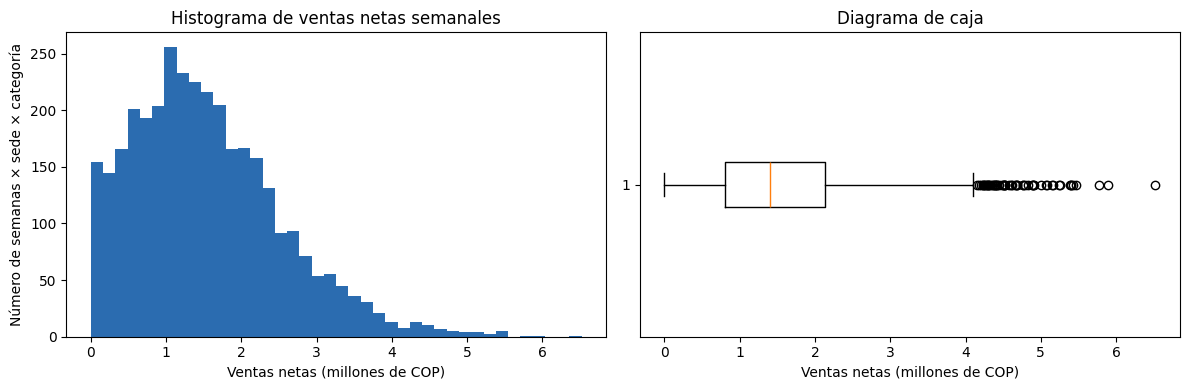

In [4]:
y = data['ventas_netas']
q1, q3 = y.quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
print(f'Mínimo {y.min():,.0f} · mediana {y.median():,.0f} · media {y.mean():,.0f} · máximo {y.max():,.0f} COP')
print(f'Atípicos (> Q3 + 1,5·RIC = {lim:,.0f} COP): {(y > lim).sum()} de {len(y)}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y / 1e6, bins=40, color='#2b6cb0'); ax[0].set_title('Histograma de ventas netas semanales'); ax[0].set_xlabel('Ventas netas (millones de COP)'); ax[0].set_ylabel('Número de semanas × sede × categoría')
ax[1].boxplot(y / 1e6, vert=False); ax[1].set_title('Diagrama de caja'); ax[1].set_xlabel('Ventas netas (millones de COP)')
plt.tight_layout(); plt.savefig(FIG / '01_distribucion_objetivo.png', dpi=130); plt.show()

### 1.4 Análisis exploratorio

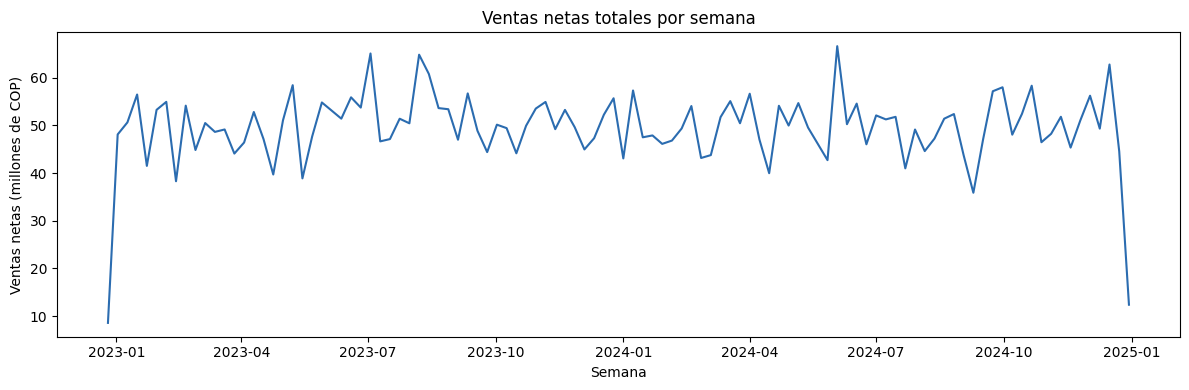

In [5]:
tot = data.groupby('semana_inicio')['ventas_netas'].sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tot.index, tot.values, color='#2b6cb0'); ax.set_title('Ventas netas totales por semana')
ax.set_xlabel('Semana'); ax.set_ylabel('Ventas netas (millones de COP)')
plt.tight_layout(); plt.savefig(FIG / '02_ventas_por_semana.png', dpi=130); plt.show()

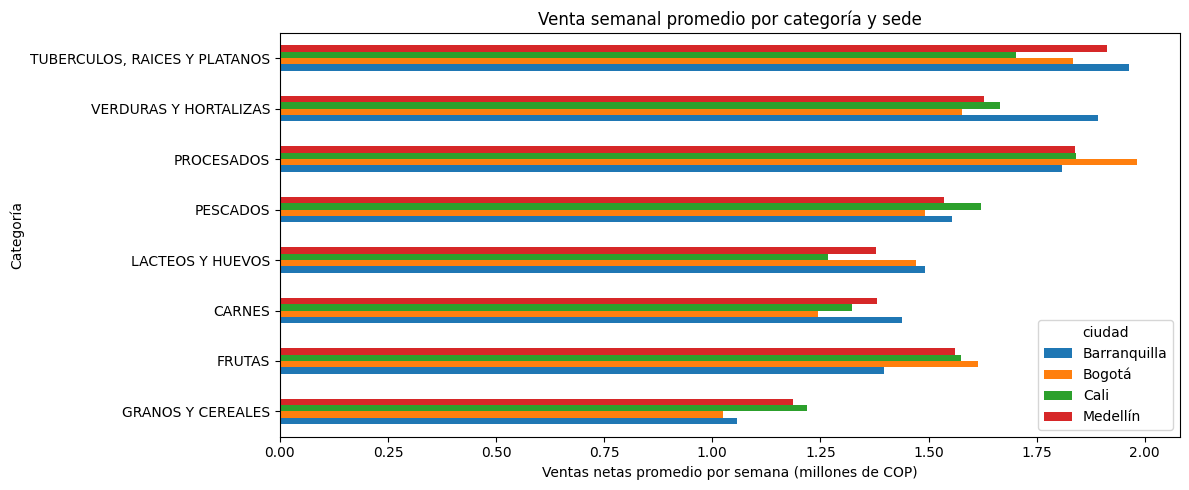

In [6]:
piv = data.groupby(['categoria', 'ciudad'])['ventas_netas'].mean().unstack() / 1e6
ax = piv.sort_values(piv.columns[0]).plot.barh(figsize=(12, 5))
ax.set_title('Venta semanal promedio por categoría y sede'); ax.set_xlabel('Ventas netas promedio por semana (millones de COP)'); ax.set_ylabel('Categoría')
plt.tight_layout(); plt.savefig(FIG / '03_promedio_categoria_sede.png', dpi=130); plt.show()

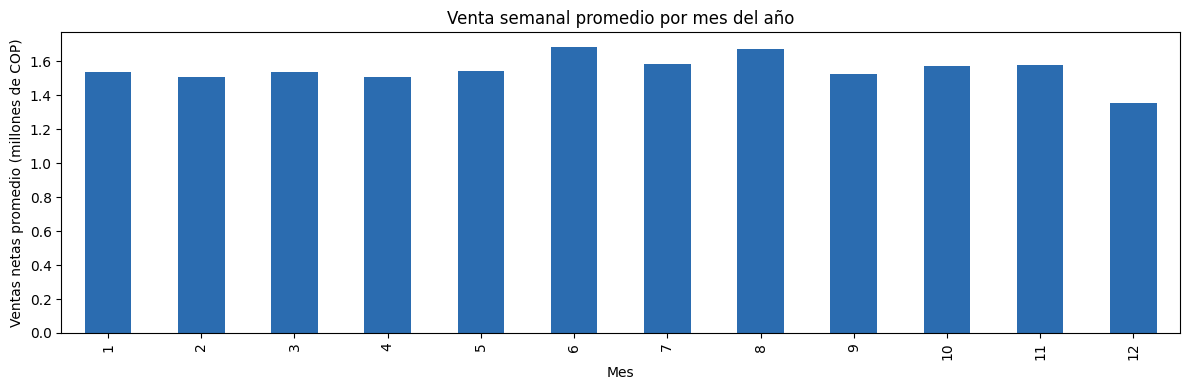

In [7]:
data['mes'] = data.semana_inicio.dt.month
mes = data.groupby('mes')['ventas_netas'].mean() / 1e6
ax = mes.plot.bar(figsize=(12, 4), color='#2b6cb0')
ax.set_title('Venta semanal promedio por mes del año'); ax.set_xlabel('Mes'); ax.set_ylabel('Ventas netas promedio (millones de COP)')
plt.tight_layout(); plt.savefig(FIG / '04_promedio_por_mes.png', dpi=130); plt.show()

## 2. Preparación de los datos
### 2.1 Variables derivadas (todas se conocen antes de la semana que se predice)
- `ventas_sem_ant`: ventas de la semana anterior, misma sede y categoría.
- `prom_4_sem`: promedio de las 4 semanas anteriores (también es la **referencia ingenua**).
- `mes`: mes de la semana (estacionalidad).
- `tendencia`: número de semana desde el inicio (crecimiento o caída).

In [8]:
data = data.sort_values(['sk_sede', 'categoria', 'semana_inicio']).reset_index(drop=True)
g = data.groupby(['sk_sede', 'categoria'])['ventas_netas']
data['ventas_sem_ant'] = g.shift(1)
data['prom_4_sem'] = g.transform(lambda s: s.shift(1).rolling(4).mean())
data['tendencia'] = (data.semana_inicio - data.semana_inicio.min()).dt.days // 7
sin_hist = data['prom_4_sem'].isna().sum()
modelo_df = data.dropna(subset=['ventas_sem_ant', 'prom_4_sem']).copy()
print(f'Filas sin 4 semanas de historia (primeras semanas de cada serie, se descartan): {sin_hist}')
print(f'Filas para modelar: {len(modelo_df):,}')

Filas sin 4 semanas de historia (primeras semanas de cada serie, se descartan): 128
Filas para modelar: 3,264


### 2.2 Atípicos, transformación logarítmica y codificación
- Atípicos: no se eliminan (son semanas reales de alta venta); se reduce su peso con la transformación `log(1 + x)` del objetivo y de los rezagos, como en el ejemplo de clase.
- Categóricas `ciudad` y `categoria`: one-hot encoding (una columna 0/1 por valor).

In [9]:
atipicos = (modelo_df['ventas_netas'] > lim).sum()
print(f'Registros atípicos conservados (tratados con log): {atipicos}')
for c in ['ventas_netas', 'ventas_sem_ant', 'prom_4_sem']:
    modelo_df['log_' + c] = np.log1p(modelo_df[c])
X_all = pd.get_dummies(modelo_df[['log_ventas_sem_ant', 'log_prom_4_sem', 'mes', 'tendencia', 'ciudad', 'categoria']],
                       columns=['ciudad', 'categoria'], dtype=int)
y_all = modelo_df['log_ventas_netas']
print('Variables de entrada:', X_all.shape[1]); list(X_all.columns)

Registros atípicos conservados (tratados con log): 56
Variables de entrada: 16


['log_ventas_sem_ant',
 'log_prom_4_sem',
 'mes',
 'tendencia',
 'ciudad_Barranquilla',
 'ciudad_Bogotá',
 'ciudad_Cali',
 'ciudad_Medellín',
 'categoria_CARNES',
 'categoria_FRUTAS',
 'categoria_GRANOS Y CEREALES',
 'categoria_LACTEOS Y HUEVOS',
 'categoria_PESCADOS',
 'categoria_PROCESADOS',
 'categoria_TUBERCULOS, RAICES Y PLATANOS',
 'categoria_VERDURAS Y HORTALIZAS']

### 2.3 División temporal: se entrena con el pasado y se prueba con el periodo más reciente

In [10]:
CORTE = pd.Timestamp('2024-07-01')
tr = modelo_df.semana_inicio < CORTE
X_tr, X_te, y_tr, y_te = X_all[tr], X_all[~tr], y_all[tr], y_all[~tr]
print(f'Entrenamiento: {tr.sum():,} filas · {modelo_df.semana_inicio[tr].min().date()} a {modelo_df.semana_inicio[tr].max().date()}')
print(f'Prueba:        {(~tr).sum():,} filas · {modelo_df.semana_inicio[~tr].min().date()} a {modelo_df.semana_inicio[~tr].max().date()}')

Entrenamiento: 2,400 filas · 2023-01-23 a 2024-06-24
Prueba:        864 filas · 2024-07-01 a 2024-12-30


## 3. Modelado
Dos algoritmos con **el mismo conjunto de entrenamiento y las mismas variables**:
- **Regresión lineal** (valores por defecto): base interpretable, vista en clase.
- **Árbol de decisión** (`max_depth=6`, `min_samples_leaf=20`, `random_state=42`): capta relaciones no lineales entre sede, categoría y estacionalidad; la profundidad limitada evita el sobreajuste.

In [11]:
modelos = {
    'Regresión lineal': LinearRegression(),
    'Árbol de decisión': DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEMILLA),
}
for m in modelos.values():
    m.fit(X_tr, y_tr)
print('Modelos entrenados')

Modelos entrenados


## 4. Evaluación sobre el conjunto de prueba (en COP, deshaciendo el logaritmo)

In [12]:
real = np.expm1(y_te).values
res, preds = [], {}
def fila(nombre, p):
    mae = mean_absolute_error(real, p); rmse = np.sqrt(mean_squared_error(real, p))
    wape = np.abs(real - p).sum() / real.sum()
    return dict(modelo=nombre, MAE=mae, RMSE=rmse, WAPE=wape, sesgo=(p - real).sum() / real.sum())
ref = modelo_df.loc[~tr, 'prom_4_sem'].values
res.append(fila('Referencia (promedio 4 semanas)', ref))
for n, m in modelos.items():
    preds[n] = np.expm1(m.predict(X_te)).clip(min=0)
    res.append(fila(n, preds[n]))
metricas = pd.DataFrame(res).set_index('modelo')
print(f'Venta real promedio por sede, categoría y semana en prueba: {real.mean():,.0f} COP')
metricas

Venta real promedio por sede, categoría y semana en prueba: 1,516,273 COP


,MAE,RMSE,WAPE,sesgo
modelo,,,,
Referencia (promedio 4 semanas),"864,435.24","1,100,063.93",0.57,0.03
Regresión lineal,"772,808.79","1,018,438.47",0.51,-0.18
Árbol de decisión,"815,926.62","1,071,662.48",0.54,-0.22


In [13]:
mejor = metricas.drop(index='Referencia (promedio 4 semanas)')['MAE'].idxmin()
mae_ref = metricas.loc['Referencia (promedio 4 semanas)', 'MAE']
print(f'Modelo elegido: {mejor} · MAE {metricas.loc[mejor, "MAE"]:,.0f} COP vs referencia {mae_ref:,.0f} COP')
print('Criterio de éxito (MAE del modelo < MAE de la referencia):', 'SÍ se alcanza' if metricas.loc[mejor, 'MAE'] < mae_ref else 'NO se alcanza')

Modelo elegido: Regresión lineal · MAE 772,809 COP vs referencia 864,435 COP
Criterio de éxito (MAE del modelo < MAE de la referencia): SÍ se alcanza


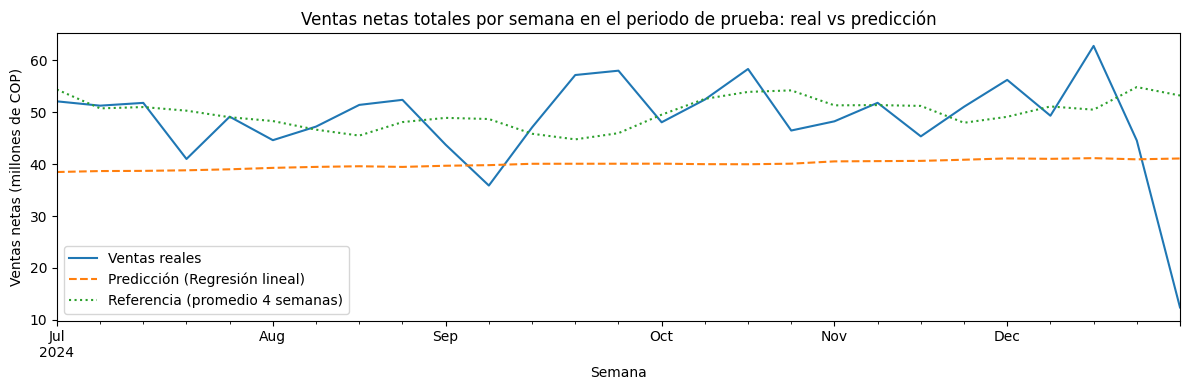

In [14]:
p = preds[mejor]
te = modelo_df.loc[~tr, ['semana_inicio']].assign(real=real, pred=p, ref=ref).groupby('semana_inicio').sum() / 1e6
ax = te.plot(figsize=(12, 4), style=['-', '--', ':'])
ax.legend(['Ventas reales', f'Predicción ({mejor})', 'Referencia (promedio 4 semanas)'])
ax.set_title('Ventas netas totales por semana en el periodo de prueba: real vs predicción'); ax.set_xlabel('Semana'); ax.set_ylabel('Ventas netas (millones de COP)')
plt.tight_layout(); plt.savefig(FIG / '05_real_vs_prediccion.png', dpi=130); plt.show()

### 4.1 Variables más importantes del modelo elegido

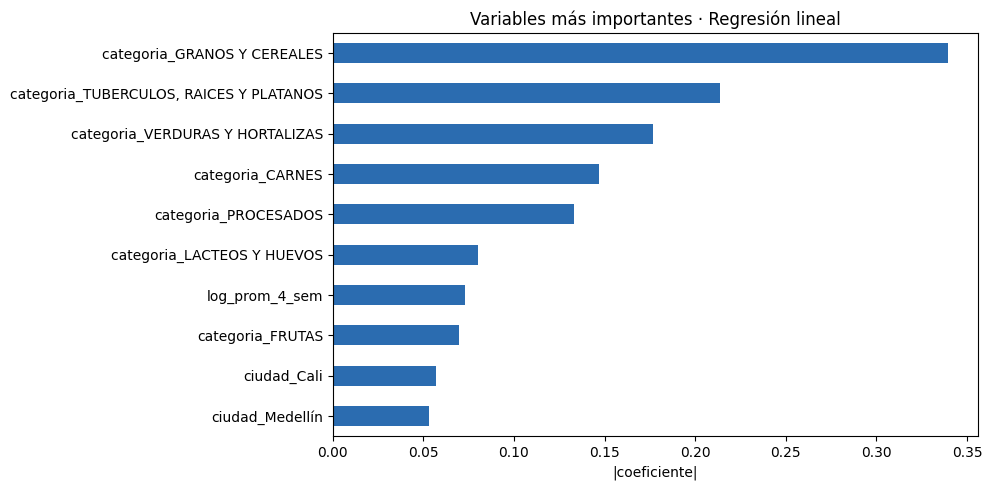

categoria_GRANOS Y CEREALES               0.34
categoria_TUBERCULOS, RAICES Y PLATANOS   0.21
categoria_VERDURAS Y HORTALIZAS           0.18
categoria_CARNES                          0.15
categoria_PROCESADOS                      0.13
categoria_LACTEOS Y HUEVOS                0.08
log_prom_4_sem                            0.07
categoria_FRUTAS                          0.07
ciudad_Cali                               0.06
ciudad_Medellín                           0.05
dtype: float64

In [15]:
m = modelos[mejor]
imp = (pd.Series(m.feature_importances_, index=X_all.columns) if hasattr(m, 'feature_importances_')
       else pd.Series(np.abs(m.coef_), index=X_all.columns)).sort_values().tail(10)
ax = imp.plot.barh(figsize=(10, 5), color='#2b6cb0')
ax.set_title(f'Variables más importantes · {mejor}'); ax.set_xlabel('Importancia' if hasattr(m, 'feature_importances_') else '|coeficiente|')
plt.tight_layout(); plt.savefig(FIG / '06_importancia_variables.png', dpi=130); plt.show()
imp.sort_values(ascending=False)

## 5. Respuesta a la pregunta de negocio: pronóstico de la semana siguiente
Se reentrena el modelo elegido con **todas** las semanas y se pronostica la semana del 6 de enero de 2025 (la siguiente a la última cargada) para cada sede y categoría.

In [16]:
final = modelos[mejor].__class__(**modelos[mejor].get_params()).fit(X_all, y_all)
ult = data.sort_values('semana_inicio').groupby(['sk_sede', 'ciudad', 'categoria']).tail(4)
nxt = ult.groupby(['sk_sede', 'ciudad', 'categoria']).agg(ventas_sem_ant=('ventas_netas', 'last'), prom_4_sem=('ventas_netas', 'mean')).reset_index()
SEM_FUT = data.semana_inicio.max() + pd.Timedelta(days=7)
nxt['semana_inicio'] = SEM_FUT; nxt['mes'] = SEM_FUT.month; nxt['tendencia'] = data.tendencia.max() + 1
Xf = pd.get_dummies(nxt.assign(log_ventas_sem_ant=np.log1p(nxt.ventas_sem_ant), log_prom_4_sem=np.log1p(nxt.prom_4_sem))[
    ['log_ventas_sem_ant', 'log_prom_4_sem', 'mes', 'tendencia', 'ciudad', 'categoria']], columns=['ciudad', 'categoria'], dtype=int)
Xf = Xf.reindex(columns=X_all.columns, fill_value=0)
nxt['ventas_predichas'] = np.expm1(final.predict(Xf)).clip(min=0)
print(f'Pronóstico total para la semana del {SEM_FUT.date()}: {nxt.ventas_predichas.sum():,.0f} COP')
nxt.pivot_table(index='categoria', columns='ciudad', values='ventas_predichas', aggfunc='sum').round(0)

Pronóstico total para la semana del 2025-01-06: 34,445,641 COP


ciudad,Barranquilla,Bogotá,Cali,Medellín
categoria,,,,
CARNES,"1,005,606.00","858,797.00","961,908.00","870,549.00"
FRUTAS,"1,089,605.00","999,536.00","1,247,394.00","998,224.00"
GRANOS Y CEREALES,"794,138.00","791,490.00","731,156.00","711,843.00"
LACTEOS Y HUEVOS,"1,048,891.00","862,336.00","1,010,061.00","986,530.00"
PESCADOS,"1,127,611.00","1,048,560.00","994,013.00","990,300.00"
PROCESADOS,"1,436,392.00","1,174,023.00","1,233,777.00","1,331,344.00"
"TUBERCULOS, RAICES Y PLATANOS","1,363,420.00","1,176,636.00","1,238,119.00","1,268,234.00"
VERDURAS Y HORTALIZAS,"1,322,979.00","1,211,580.00","1,250,657.00","1,309,933.00"


## 6. Despliegue: tabla `pred_ventas_semana` en el data warehouse

In [17]:
ddl = Path('../dw/ddl/08_pred_ventas_semana.sql').read_text(encoding='utf-8')
with engine.begin() as c:
    for stmt in [s for s in ddl.split(';') if s.strip() and not s.strip().upper().startswith('USE')]:
        c.execute(text(stmt))
    c.execute(text('DELETE FROM pred_ventas_semana'))
ahora = pd.Timestamp.now().floor('s')
prueba = modelo_df.loc[~tr, ['semana_inicio', 'sk_sede', 'ciudad', 'categoria']].assign(
    tipo_registro='prueba', ventas_reales=real, ventas_predichas=preds[mejor], ventas_referencia=ref)
futuro = nxt[['semana_inicio', 'sk_sede', 'ciudad', 'categoria', 'ventas_predichas']].assign(
    tipo_registro='pronostico', ventas_reales=None, ventas_referencia=nxt.prom_4_sem)
salida = pd.concat([prueba, futuro], ignore_index=True)
salida['sk_tiempo'] = salida.semana_inicio.dt.strftime('%Y%m%d').astype(int)
salida['modelo'] = mejor; salida['fecha_generacion'] = ahora
salida = salida.round({'ventas_reales': 2, 'ventas_predichas': 2, 'ventas_referencia': 2})
salida.to_sql('pred_ventas_semana', engine, if_exists='append', index=False)
with engine.connect() as c:
    print(c.execute(text('SELECT tipo_registro, COUNT(*), ROUND(SUM(ventas_predichas)) FROM pred_ventas_semana GROUP BY tipo_registro')).fetchall())

[('prueba', 864, Decimal('1079400442')), ('pronostico', 32, Decimal('34445641'))]


C:\Users\yefry\AppData\Local\Temp\ipykernel_19756\3579103849.py:11: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  salida = pd.concat([prueba, futuro], ignore_index=True)
